# Select the Forge study panel

I am selecting a fixed panel of item markets to study changes in price and trading activity in The Forge. The selection window is **June 1 through September 30, 2022**, inclusive. These dates were chosen because this is a decently long period of time between any significant updates.

The panel combines eight minerals with the top 50 manufactured Tech I products by market-history order count and the top 50 by estimated traded ISK. I will deduplicate the combined lists and freeze the selected type IDs before examining later market movements.

I use the available reference data for historical classification, assuming it has not changed significantly apart from additions and published-status changes.

## Data and scope

Market history and item references are accessed through the project's read-only analytical connection. Item names and classifications come from reference data; manufacturing blueprint products identify which items can be manufactured.

In [1]:
import json
import tarfile
from contextlib import contextmanager
from datetime import UTC, date, datetime

import pandas as pd
import requests

from transform.notebook_access import open_analysis_connection

REGION_ID = 10000002
SELECTION_START = date(2022, 6, 1)
SELECTION_END = date(2022, 9, 30)
TOP_N = 50
SELECTION_DAYS = (SELECTION_END - SELECTION_START).days + 1

## Manufactured Tech I candidates

The proposed candidate set consists of published item types with an explicit Tech I classification (`meta_group_id = 1`) that also appear as manufacturing blueprint products. Each product appears once, even if multiple blueprints produce it.

I use [Everef's reference extract](https://docs.everef.net/datasets/reference-data) to identify manufacturing products, then join those IDs to the published item references. The extract is fetched once when the download cell runs and reused in memory for the analysis.

Classification exceptions and missing reference fields are reviewed before finalizing the candidate set.

In [2]:
REFERENCE_URL = "https://data.everef.net/reference-data/history/2026/reference-data-2026-09-30.tar.xz"

blueprints = None
with requests.get(REFERENCE_URL, stream=True, timeout=(10, 120)) as response:
    response.raise_for_status()
    response.raw.decode_content = True
    with tarfile.open(fileobj=response.raw, mode="r|xz") as archive:
        for member in archive:
            if member.name.removeprefix("./") == "blueprints.json" and member.isfile():
                with archive.extractfile(member) as blueprint_file:
                    blueprints = json.load(blueprint_file)
                break

if not isinstance(blueprints, dict) or not blueprints:
    raise ValueError("Reference extract must contain a nonempty blueprints.json object.")

reference_retrieved_at = datetime.now(UTC)

In [3]:
product_ids = set()
blueprints_without_products = []

for blueprint_id, blueprint in blueprints.items():
    if not isinstance(blueprint, dict) or not isinstance(blueprint.get("activities"), dict):
        raise ValueError(f"Invalid activities for blueprint {blueprint_id}.")
    activities = blueprint["activities"]
    if "manufacturing" not in activities:
        continue
    manufacturing = activities["manufacturing"]
    if not isinstance(manufacturing, dict):
        raise ValueError(f"Invalid manufacturing products for blueprint {blueprint_id}.")
    products = manufacturing.get("products")
    if products is None or products == {}:
        blueprints_without_products.append(int(blueprint_id))
        continue
    if not isinstance(products, dict):
        raise ValueError(f"Invalid manufacturing products for blueprint {blueprint_id}.")
    for product_key, product in products.items():
        type_id = product.get("type_id") if isinstance(product, dict) else None
        if type(type_id) is not int or type_id <= 0 or str(type_id) != product_key:
            raise ValueError(f"Invalid product {product_key} for blueprint {blueprint_id}.")
        product_ids.add(type_id)

if not product_ids:
    raise ValueError("No manufacturing products found in the reference extract.")

manufacturing_product_ids = pd.DataFrame({"type_id": list(product_ids)}, dtype="int64")

pd.Series(
    {
        "Source URL": REFERENCE_URL,
        "Retrieved at (UTC)": reference_retrieved_at.isoformat(),
        "Blueprint records": len(blueprints),
        "Unique manufacturing products": len(manufacturing_product_ids),
        "Blueprints without manufacturing products": len(blueprints_without_products),
    },
    name="Manufacturing reference input",
)

Source URL                                   https://data.everef.net/reference-data/history...
Retrieved at (UTC)                                            2026-10-01T22:05:07.424662+00:00
Blueprint records                                                                         5082
Unique manufacturing products                                                             4841
Blueprints without manufacturing products                                                   23
Name: Manufacturing reference input, dtype: object

In [4]:
pd.DataFrame({"blueprint_id_without_products": blueprints_without_products}, dtype="int64")

,blueprint_id_without_products
0,37011
1,37012
2,37014
3,37015
4,37069
5,37074
6,37287
7,37311
8,37312
9,37314


In [5]:
@contextmanager
def open_study_connection():
    with open_analysis_connection() as con:
        con.register("manufacturing_product_ids", manufacturing_product_ids)
        yield con

## Selection-window activity

I rank candidates separately by two measures of activity in The Forge during the selection window:

- **History order count:** the sum of daily market-history `order_count`, not the number of standing orders.
- **Estimated traded ISK:** the sum of daily VWAP multiplied by daily traded volume. This is an estimate rather than transaction-level traded value.

The ISK ranking requires at least as many total history orders as calendar days in the inclusive selection window: 122 for this window. This applies before ranking and does not require trading on every day. The order-count ranking has no additional activity filter.

Each list is ordered by its activity measure alone. Tied items share a rank; if a tie crosses the top-50 cutoff, all affected items remain visible for review before membership is frozen.

In [6]:
activity_sql = """
with candidates as (
    select t.type_id, t.name_en as type_name
    from stg_everef_ref_types as t
    inner join manufacturing_product_ids as p on t.type_id = p.type_id
    where t.published = true and t.meta_group_id = 1
),

window_history as (
    select type_id, market_date, order_count, estimated_traded_isk
    from int_forge_market_history
    where region_id = $region_id
        and market_date between $selection_start and $selection_end
),

activity_totals as (
    select
        c.type_id,
        c.type_name,
        count(h.market_date) as source_row_count,
        case when count(h.market_date) = 0 then 0
            else sum(h.order_count) end as total_order_count,
        case when count(h.market_date) = 0 then 0
            else sum(h.estimated_traded_isk) end as total_estimated_traded_isk
    from candidates as c
    left join window_history as h on c.type_id = h.type_id
    group by c.type_id, c.type_name
),

isk_eligible as (
    select h.type_id, sum(h.estimated_traded_isk) as total_estimated_traded_isk
    from window_history as h
    inner join candidates as c on h.type_id = c.type_id
    group by h.type_id
    having sum(h.order_count) >= $selection_days
),
isk_ranks as (
    select type_id,
        rank() over (order by total_estimated_traded_isk desc nulls last) as estimated_traded_isk_rank
    from isk_eligible
)
select
    a.*,
    rank() over (order by a.total_order_count desc nulls last) as order_count_rank,
    i.estimated_traded_isk_rank
from activity_totals as a
left join isk_ranks as i on a.type_id = i.type_id
"""

with open_study_connection() as con:
    activity = con.execute(
        activity_sql,
        {
            "region_id": REGION_ID,
            "selection_start": SELECTION_START,
            "selection_end": SELECTION_END,
            "selection_days": SELECTION_DAYS,
        },
    ).df()

if activity.empty or activity["source_row_count"].sum() == 0:
    raise ValueError("No candidate market history is available in the selection window.")

top_by_order_count = activity.loc[activity["order_count_rank"] <= TOP_N].sort_values(
    "total_order_count", ascending=False
)
top_by_estimated_isk = activity.loc[activity["estimated_traded_isk_rank"] <= TOP_N].sort_values(
    "total_estimated_traded_isk", ascending=False
)

pd.DataFrame(
    {
        "ranking": ["History order count", "Estimated traded ISK"],
        "items_shown": [len(top_by_order_count), len(top_by_estimated_isk)],
        "cutoff_tie_requires_review": [
            len(top_by_order_count) > TOP_N,
            len(top_by_estimated_isk) > TOP_N,
        ],
    }
)

,ranking,items_shown,cutoff_tie_requires_review
0,History order count,50,False
1,Estimated traded ISK,50,False


In [7]:
from IPython.display import display

for title, ranked in [
    ("History order count ranking", top_by_order_count),
    ("Estimated traded ISK ranking", top_by_estimated_isk),
]:
    display(
        ranked.drop(columns="source_row_count").style.hide(axis="index").format(
            {
                "total_order_count": "{:,.0f}",
                "total_estimated_traded_isk": "{:,.0f}",
            },
            na_rep="Unavailable",
        ).set_caption(title)
    )

type_id,type_name,total_order_count,total_estimated_traded_isk,order_count_rank,estimated_traded_isk_rank
17938,Core Probe Launcher I,"118,849","4,761,850,090",1,364
30013,Core Scanner Probe I,"95,460","35,204,122,670",2,125
2454,Hobgoblin I,"88,160","3,805,769,860",3,397
222,Antimatter Charge S,"77,502","10,789,093,003",4,258
4403,Reactive Armor Hardener,"75,468","178,205,678,100",5,40
25861,Salvager I,"72,717","11,855,225,890",6,246
22175,Data Analyzer I,"67,157","5,414,072,060",7,348
11370,Prototype Cloaking Device I,"66,592","310,989,590,000",8,26
33180,Scan Rangefinding Array I,"64,881","18,414,418,500",9,200
22177,Relic Analyzer I,"62,531","4,644,134,530",10,370


type_id,type_name,total_order_count,total_estimated_traded_isk,order_count_rank,estimated_traded_isk_rank
20185,Charon,"1,294","3,173,255,006,000",497,1
20183,Providence,785,"2,008,259,000,000",572,2
20187,Obelisk,758,"1,891,283,000,000",577,3
35833,Fortizar,240,"1,849,922,000,000",767,4
638,Raven,"4,373","1,366,540,700,292",321,5
20189,Fenrir,499,"1,245,364,000,000",641,6
645,Dominix,"3,447","1,081,954,600,000",352,7
639,Tempest,"3,019","1,020,872,717,001",372,8
47270,Vedmak,"11,793","941,718,800,000",152,9
641,Megathron,"2,725","817,551,900,000",388,10


The charts show each ranked list on its own scale. Labels include type IDs to distinguish items with the same name.

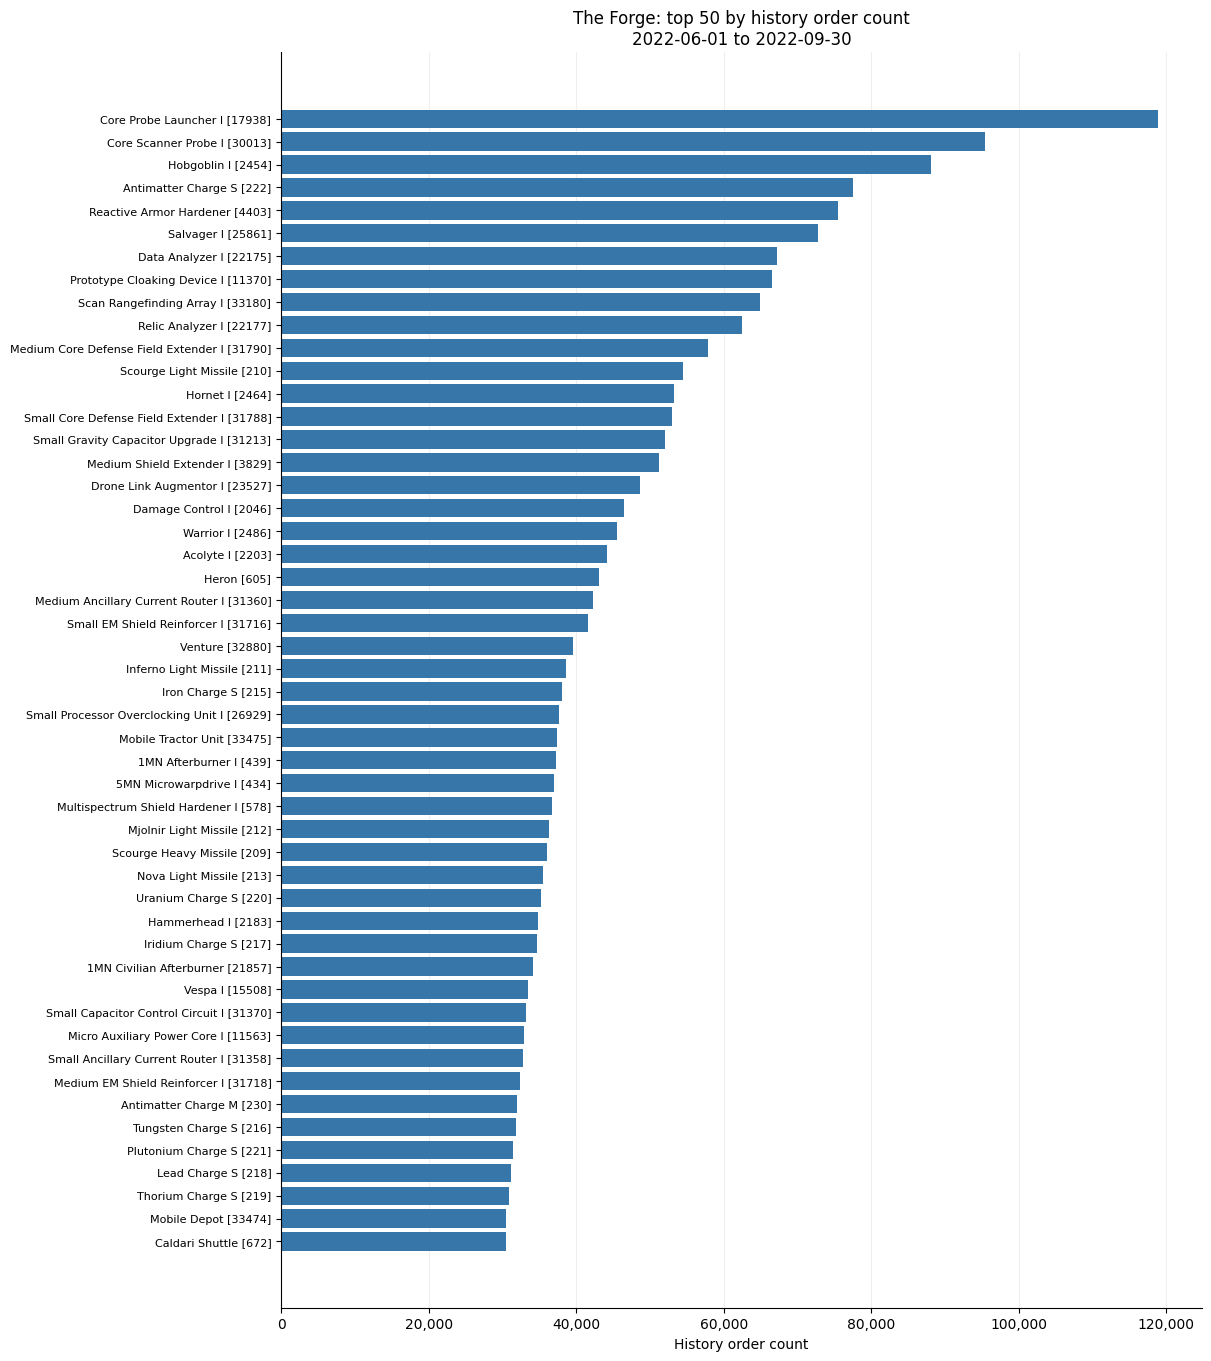

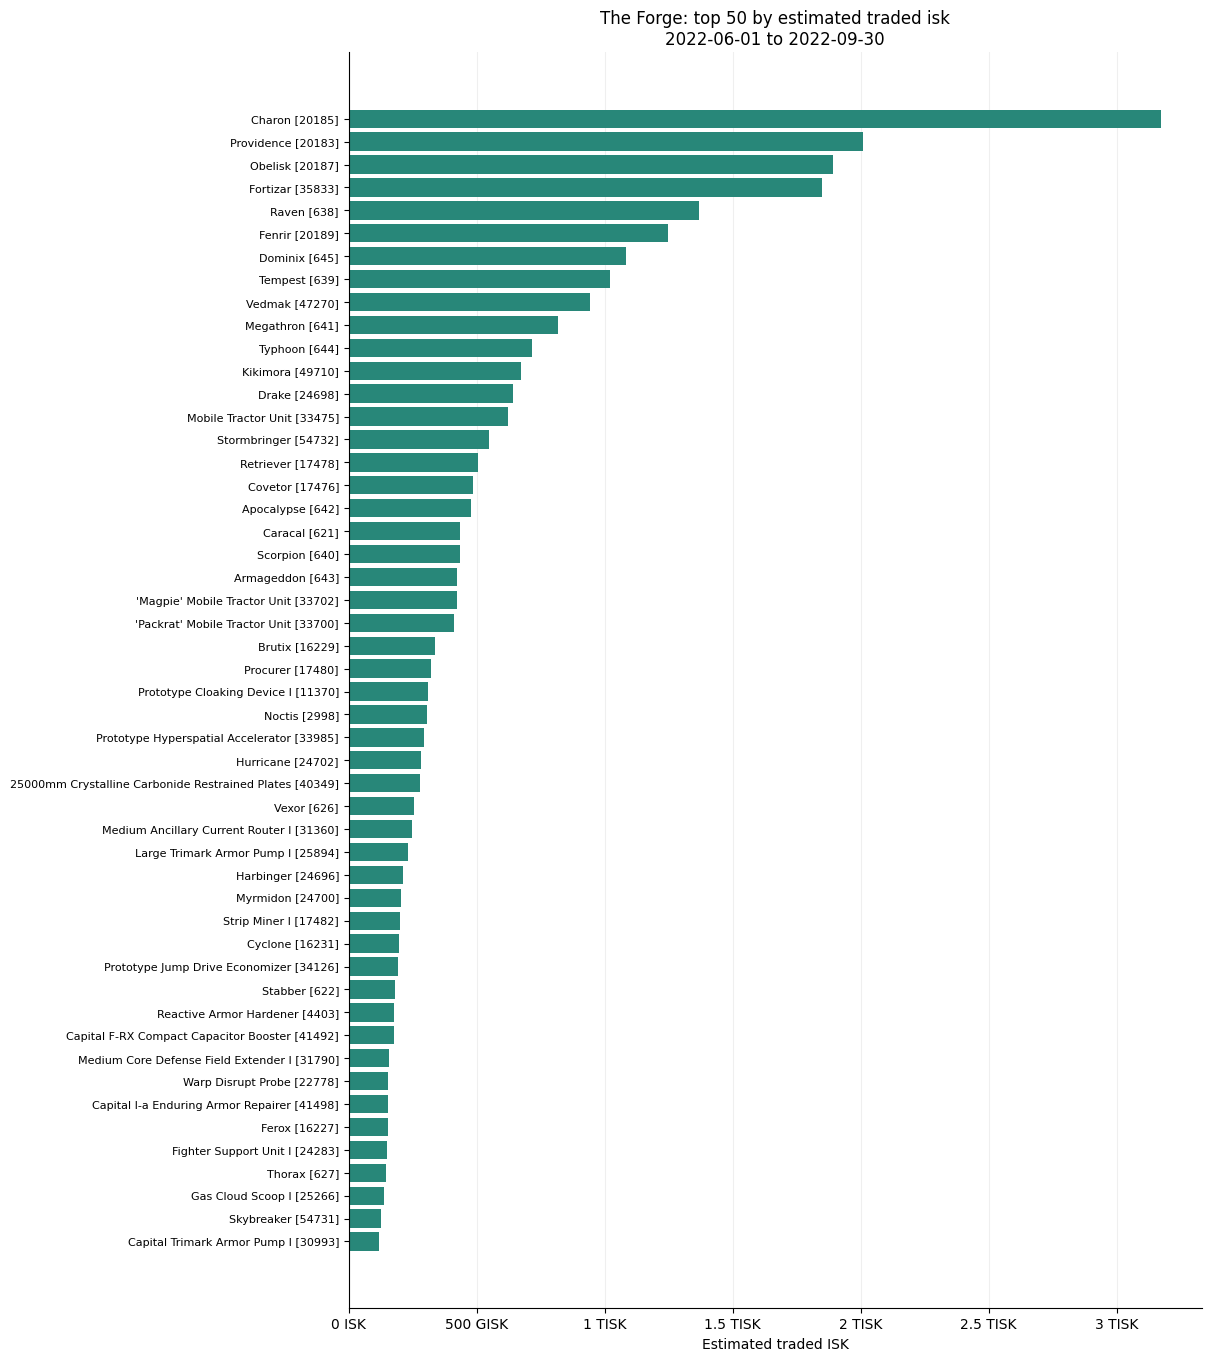

In [8]:
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter, FuncFormatter

for ranked, metric, title, color in [
    (top_by_order_count, "total_order_count", "History order count", "#3676a8"),
    (top_by_estimated_isk, "total_estimated_traded_isk", "Estimated traded ISK", "#288779"),
]:
    labels = (
        ranked["type_name"].fillna("Name unavailable")
        + " [" + ranked["type_id"].astype(str) + "]"
    )
    fig, ax = plt.subplots(figsize=(12, max(5, len(ranked) * 0.27)), layout="constrained")
    ax.barh(range(len(ranked)), ranked[metric], color=color)
    ax.set_yticks(range(len(ranked)), labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(left=0)
    ax.set_xlabel(title)
    if metric == "total_estimated_traded_isk":
        ax.xaxis.set_major_formatter(EngFormatter(unit="ISK"))
    else:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
    suffix = " — cutoff tie pending review" if len(ranked) > TOP_N else ""
    ax.set_title(
        f"The Forge: top {TOP_N} by {title.lower()}{suffix}\n"
        f"{SELECTION_START:%Y-%m-%d} to {SELECTION_END:%Y-%m-%d}"
    )
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

## Study-panel membership

I combine both top-50 lists with Tritanium, Pyerite, Mexallon, Isogen, Nocxium, Zydrine, Megacyte, and Morphite, then remove duplicate type IDs.

The notebook retains ranks, totals, and selection reasons for review. I assign study categories manually and export the selected IDs and categories to the dbt seed `forge_study_panel`. Running the export cell regenerates the seed; categories describe the panel without affecting selection. The history section uses the dbt models after they have been rebuilt with this seed.

In [9]:
MINERAL_IDS = [34, 35, 36, 37, 38, 39, 40, 11399]

if len(top_by_order_count) != TOP_N or len(top_by_estimated_isk) != TOP_N:
    raise ValueError("Resolve the top-50 list sizes before freezing membership.")

membership = pd.concat(
    [
        pd.DataFrame({"type_id": MINERAL_IDS, "selection_reason": "curated mineral"}),
        top_by_order_count[["type_id"]].assign(selection_reason="top 50 history order count"),
        top_by_estimated_isk[["type_id"]].assign(selection_reason="top 50 estimated traded ISK"),
    ],
    ignore_index=True,
)

panel_sql = """
with members as (
    select
        type_id,
        bool_or(selection_reason = 'curated mineral') as is_mineral,
        bool_or(selection_reason = 'top 50 history order count') as in_order_count_top_50,
        bool_or(selection_reason = 'top 50 estimated traded ISK') as in_estimated_isk_top_50,
        string_agg(selection_reason, '; ' order by selection_reason) as selection_reason
    from membership
    group by type_id
),
window_totals as (
    select
        m.type_id,
        case when count(h.market_date) = 0 then 0
            else sum(h.order_count) end as total_order_count,
        case when count(h.market_date) = 0 then 0
            else sum(h.estimated_traded_isk) end as total_estimated_traded_isk
    from members as m
    left join int_forge_market_history as h
        on m.type_id = h.type_id
        and h.region_id = $region_id
        and h.market_date between $selection_start and $selection_end
    group by m.type_id
)
select
    m.*,
    t.name_en as type_name,
    a.order_count_rank,
    a.estimated_traded_isk_rank,
    w.total_order_count,
    w.total_estimated_traded_isk
from members as m
left join stg_everef_ref_types as t on m.type_id = t.type_id
left join activity as a on m.type_id = a.type_id
left join window_totals as w on m.type_id = w.type_id
"""

with open_study_connection() as con:
    con.register("membership", membership)
    con.register("activity", activity)
    proposed_panel = con.execute(
        panel_sql,
        {"region_id": REGION_ID, "selection_start": SELECTION_START, "selection_end": SELECTION_END},
    ).df()

assert proposed_panel["type_id"].is_unique
assert set(MINERAL_IDS).issubset(proposed_panel["type_id"])
assert proposed_panel["in_order_count_top_50"].sum() == TOP_N
assert proposed_panel["in_estimated_isk_top_50"].sum() == TOP_N
proposed_panel["region_id"] = REGION_ID
proposed_panel["selection_start"] = SELECTION_START.isoformat()
proposed_panel["selection_end"] = SELECTION_END.isoformat()

In [10]:
from pathlib import Path

category_ids = {
    "Minerals": [34, 35, 36, 37, 38, 39, 40, 11399],
    "Ammunition and probes": [209, 210, 211, 212, 213, 215, 216, 217, 218, 219, 220, 221, 222, 230, 22778, 30013],
    "Drones": [2183, 2203, 2454, 2464, 2486, 15508],
    "Deployables": [33474, 33475, 33700, 33702],
    "Structures": [35833],
    "Rigs": [25894, 26929, 30993, 31213, 31358, 31360, 31370, 31716, 31718, 31788, 31790],
    "Ships": [605, 621, 622, 626, 627, 638, 639, 640, 641, 642, 643, 644, 645, 672, 2998, 16227, 16229, 16231, 17476, 17478, 17480, 20183, 20185, 20187, 20189, 24696, 24698, 24700, 24702, 32880, 47270, 49710, 54731, 54732],
    "Modules": [434, 439, 578, 2046, 3829, 4403, 11370, 11563, 17482, 17938, 21857, 22175, 22177, 23527, 24283, 25266, 25861, 33180, 33985, 34126, 40349, 41492, 41498],
}
assignments = pd.DataFrame(
    [(type_id, category) for category, ids in category_ids.items() for type_id in ids],
    columns=["type_id", "study_category"],
)
if not assignments["type_id"].is_unique:
    raise ValueError("A type ID has more than one study category.")
study_panel = proposed_panel[["type_id", "type_name"]].merge(
    assignments, on="type_id", how="left", validate="one_to_one"
)
unassigned = study_panel.loc[study_panel["study_category"].isna(), ["type_id", "type_name"]]
if not unassigned.empty:
    display(unassigned)
    raise ValueError("Assign a study category to each selected item before exporting.")
seed = study_panel[["type_id", "study_category"]].sort_values("type_id").reset_index(drop=True)
repo_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "transformation" / "dbt_project.yml").is_file()
)
seed_path = repo_root / "transformation" / "seeds" / "forge_study_panel.csv"
seed.to_csv(seed_path, index=False, lineterminator="\n")

display(pd.Series(
    {
        "Frozen panel items": len(study_panel),
        "Curated minerals": int(study_panel["type_id"].isin(MINERAL_IDS).sum()),
        "In both ranked lists": int((
            proposed_panel["in_order_count_top_50"] & proposed_panel["in_estimated_isk_top_50"]
        ).sum()),
        "Unavailable names": int(study_panel["type_name"].isna().sum()),
        "Generated seed": str(seed_path.relative_to(repo_root)),
    }, name="Study panel",
))
display(study_panel.groupby("study_category").size().rename("Items"))
display(proposed_panel.merge(study_panel[["type_id", "study_category"]], on="type_id")
        .style.hide(axis="index").format(
    {
        "order_count_rank": "{:.0f}",
        "estimated_traded_isk_rank": "{:.0f}",
        "total_order_count": "{:,.0f}",
        "total_estimated_traded_isk": "{:,.0f}",
    }, na_rep="Unavailable",
))

Frozen panel items                                             103
Curated minerals                                                 8
In both ranked lists                                             5
Unavailable names                                                0
Generated seed          transformation/seeds/forge_study_panel.csv
Name: Study panel, dtype: object

study_category
Ammunition and probes    16
Deployables               4
Drones                    6
Minerals                  8
Modules                  23
Rigs                     11
Ships                    34
Structures                1
Name: Items, dtype: int64

type_id,is_mineral,in_order_count_top_50,in_estimated_isk_top_50,selection_reason,type_name,order_count_rank,estimated_traded_isk_rank,total_order_count,total_estimated_traded_isk,region_id,selection_start,selection_end,study_category
209,False,True,False,top 50 history order count,Scourge Heavy Missile,33,199,"36,006","18,489,879,920",10000002,2022-06-01,2022-09-30,Ammunition and probes
210,False,True,False,top 50 history order count,Scourge Light Missile,12,360,"54,525","4,913,811,287",10000002,2022-06-01,2022-09-30,Ammunition and probes
211,False,True,False,top 50 history order count,Inferno Light Missile,25,485,"38,602","2,312,362,614",10000002,2022-06-01,2022-09-30,Ammunition and probes
212,False,True,False,top 50 history order count,Mjolnir Light Missile,32,432,"36,351","3,176,092,979",10000002,2022-06-01,2022-09-30,Ammunition and probes
213,False,True,False,top 50 history order count,Nova Light Missile,34,342,"35,528","5,630,276,839",10000002,2022-06-01,2022-09-30,Ammunition and probes
215,False,True,False,top 50 history order count,Iron Charge S,26,623,"38,088","878,166,236",10000002,2022-06-01,2022-09-30,Ammunition and probes
216,False,True,False,top 50 history order count,Tungsten Charge S,45,695,"31,832","426,212,272",10000002,2022-06-01,2022-09-30,Ammunition and probes
217,False,True,False,top 50 history order count,Iridium Charge S,37,668,"34,656","541,016,316",10000002,2022-06-01,2022-09-30,Ammunition and probes
218,False,True,False,top 50 history order count,Lead Charge S,47,675,"31,183","508,625,714",10000002,2022-06-01,2022-09-30,Ammunition and probes
219,False,True,False,top 50 history order count,Thorium Charge S,48,708,"30,896","378,142,832",10000002,2022-06-01,2022-09-30,Ammunition and probes


## Historical source-row presence

I summarize the selected items' available history using observed date ranges and source-row counts. These describe the panel rather than determine membership.

The table and chart count observed source rows from June 2022 through the available cutoff. An empty month means no observed rows, not proof that the item existed or had no activity. First observation is not treated as an introduction date.

For the study's applicable item-date grid, an absent source row means missing price and zero volume and order count. Observed values, including nulls and zeros, are preserved. Dates before an item's introduction are not applicable rather than missing. This section describes source-row presence without constructing that analytical grid.

In [11]:
history_summary_sql = """
select
    p.type_id,
    p.type_name,
    min(h.market_date) as first_observed_date,
    max(h.market_date) as last_observed_date,
    count(h.market_date) as source_row_count
from int_study_panel as p
left join int_study_panel_history as h
    on p.type_id = h.type_id
    and h.region_id = $region_id
    and h.market_date >= $history_start
group by p.type_id, p.type_name
"""

monthly_presence_sql = """
select
    h.type_id,
    cast(date_trunc('month', h.market_date) as date) as month,
    count(*) as source_row_count
from int_study_panel_history as h
where h.region_id = $region_id and h.market_date >= $history_start
group by h.type_id, date_trunc('month', h.market_date)
"""

with open_analysis_connection() as con:
    built_panel = con.execute("select type_id, study_category from int_study_panel").df()
    built_membership = built_panel.sort_values("type_id").reset_index(drop=True)
    if not built_membership.equals(seed):
        raise ValueError("Rebuild dbt with the generated seed before analyzing history.")
    parameters = {"region_id": REGION_ID, "history_start": SELECTION_START}
    history_summary = con.execute(history_summary_sql, parameters).df()
    monthly_presence = con.execute(monthly_presence_sql, parameters).df()

available_cutoff = history_summary["last_observed_date"].max()
if pd.isna(available_cutoff):
    raise ValueError("No observed history is available for the frozen panel.")
display(pd.Series({"Latest observed panel date": available_cutoff.date()}))
display(history_summary.style.hide(axis="index").format(na_rep="Unavailable"))

Latest observed panel date    2026-09-01
dtype: object

type_id,type_name,first_observed_date,last_observed_date,source_row_count
218,Lead Charge S,2022-06-01 00:00:00,2026-09-01 00:00:00,1552
49710,Kikimora,2022-06-01 00:00:00,2026-09-01 00:00:00,1552
11399,Morphite,2022-06-01 00:00:00,2026-09-01 00:00:00,1552
30013,Core Scanner Probe I,2022-06-01 00:00:00,2026-09-01 00:00:00,1552
17938,Core Probe Launcher I,2022-06-01 00:00:00,2026-09-01 00:00:00,1552
41492,Capital F-RX Compact Capacitor Booster,2022-06-01 00:00:00,2026-09-01 00:00:00,1551
36,Mexallon,2022-06-01 00:00:00,2026-09-01 00:00:00,1552
21857,1MN Civilian Afterburner,2022-06-01 00:00:00,2026-09-01 00:00:00,1552
230,Antimatter Charge M,2022-06-01 00:00:00,2026-09-01 00:00:00,1552
626,Vexor,2022-06-01 00:00:00,2026-09-01 00:00:00,1551


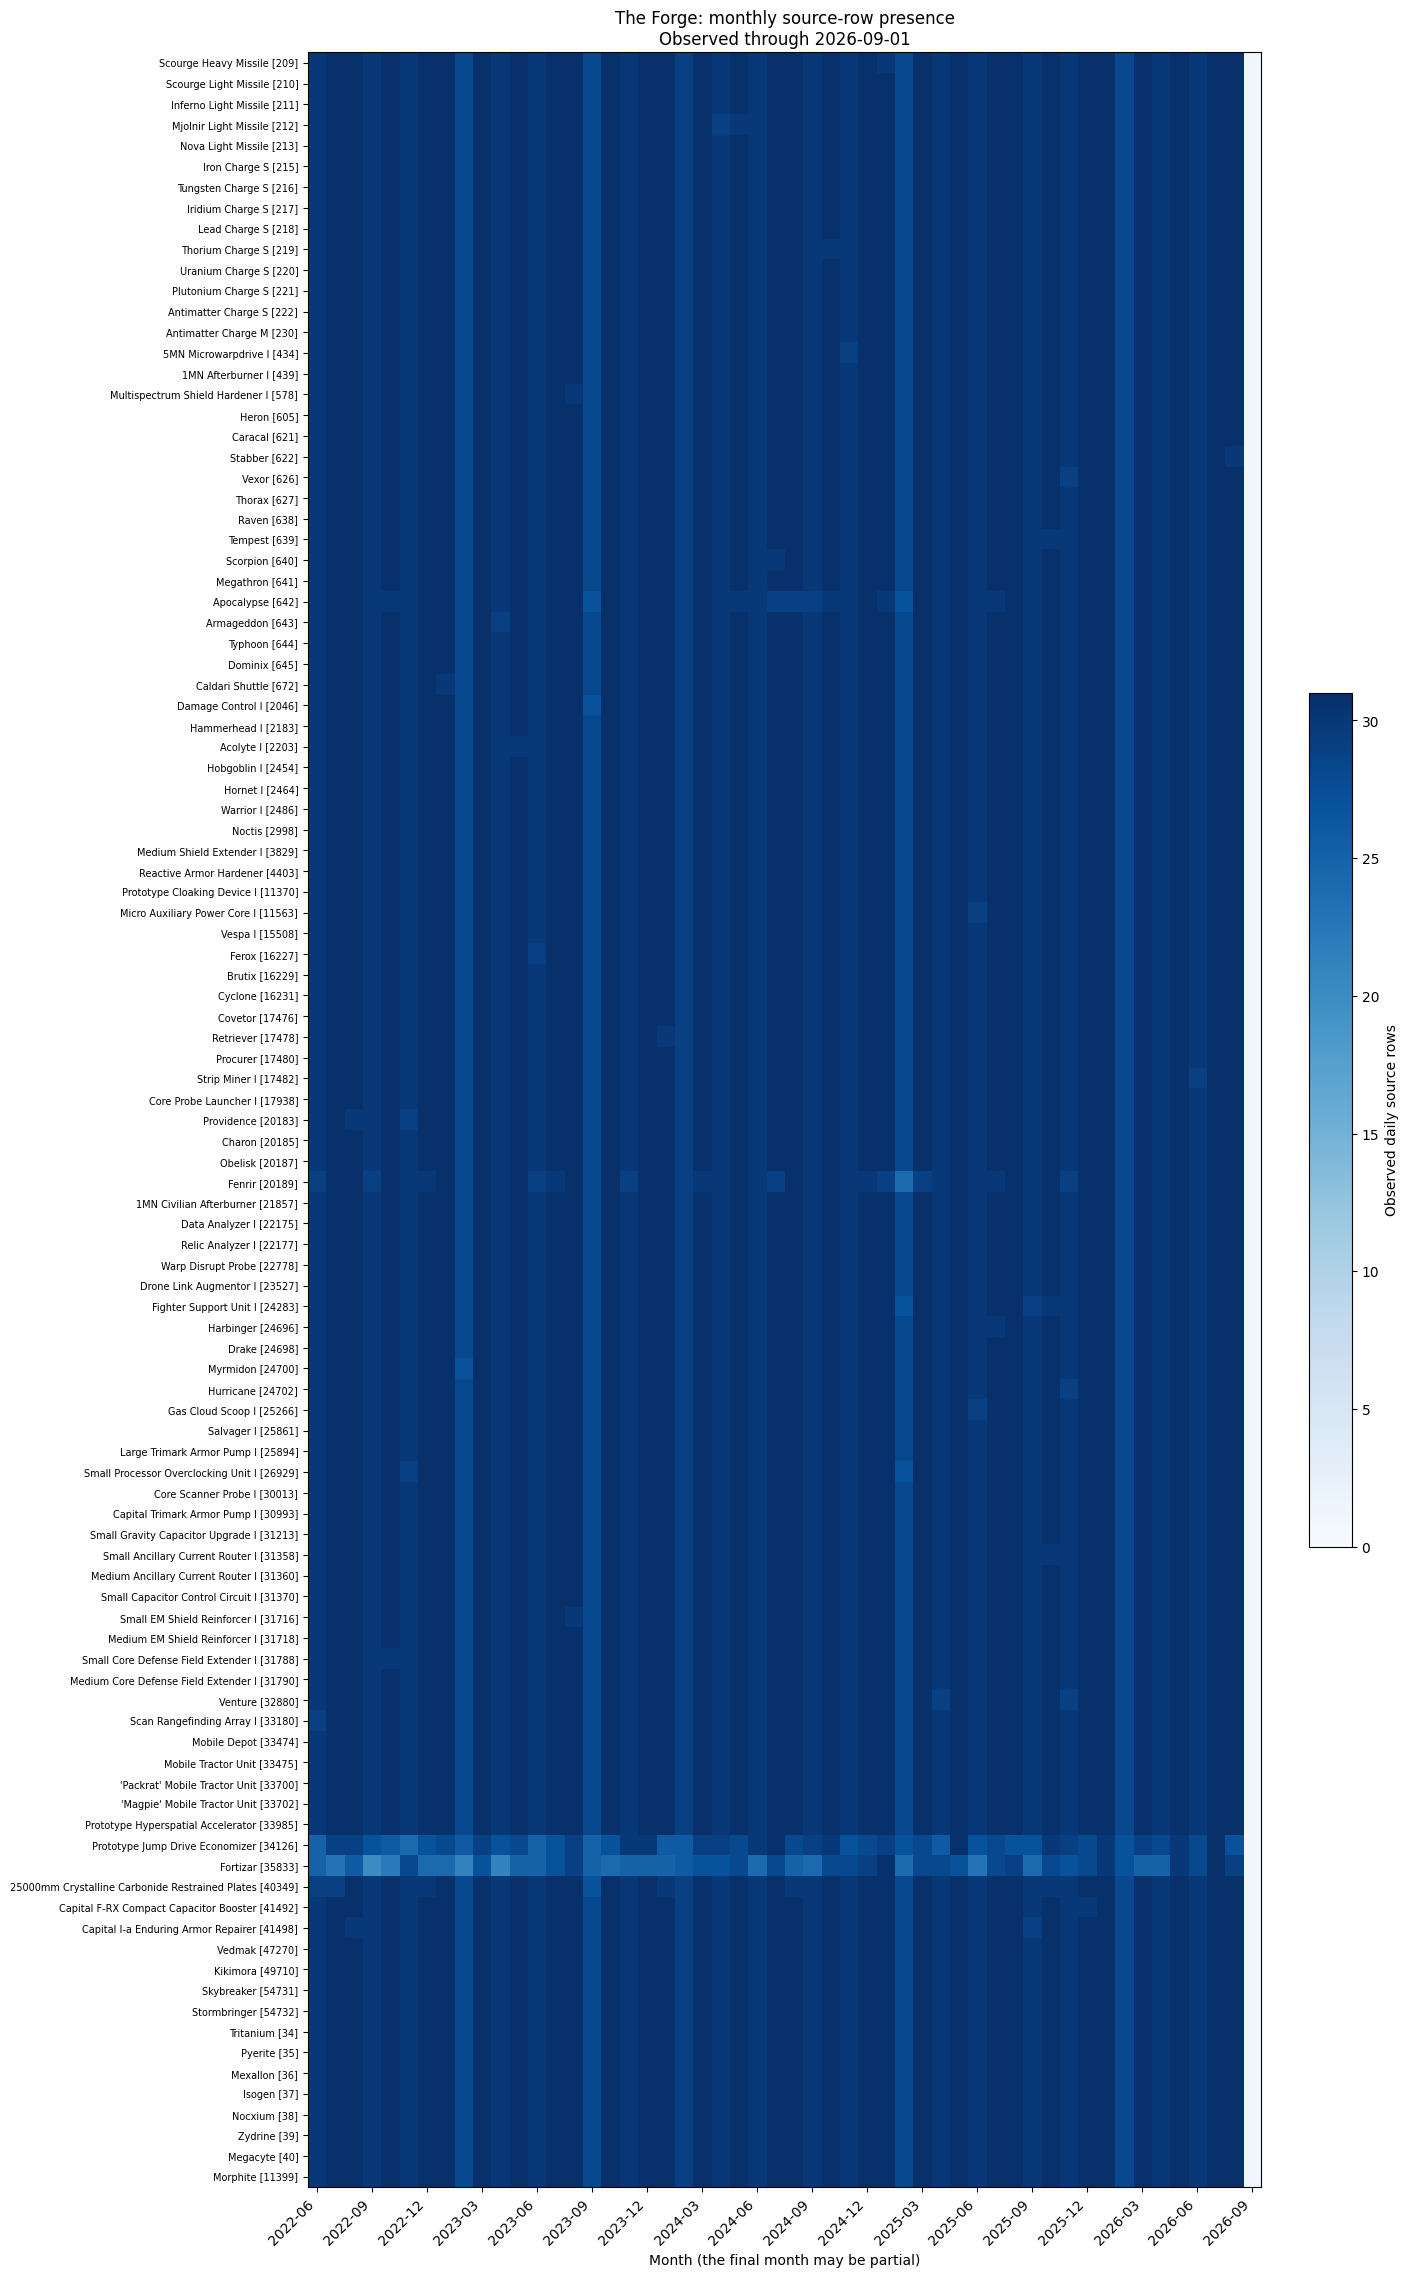

In [12]:
months = pd.date_range(SELECTION_START, available_cutoff, freq="MS")
presence_matrix = monthly_presence.pivot(
    index="type_id", columns="month", values="source_row_count"
).reindex(index=study_panel["type_id"], columns=months).fillna(0)
labels = (
    study_panel["type_name"].fillna("Name unavailable")
    + " [" + study_panel["type_id"].astype(str) + "]"
)
fig, ax = plt.subplots(figsize=(14, max(6, len(study_panel) * 0.22)), layout="constrained")
image = ax.imshow(presence_matrix.to_numpy(), aspect="auto", interpolation="nearest",
                  cmap="Blues", vmin=0, vmax=31)
ax.set_yticks(range(len(labels)), labels, fontsize=7)
tick_positions = list(range(0, len(months), 3))
ax.set_xticks(tick_positions, months[tick_positions].strftime("%Y-%m"), rotation=45, ha="right")
ax.set_title(f"The Forge: monthly source-row presence\nObserved through {available_cutoff:%Y-%m-%d}")
ax.set_xlabel("Month (the final month may be partial)")
fig.colorbar(image, ax=ax, label="Observed daily source rows", shrink=0.4)
plt.show()